# Assignment 1: Smart Room Temperature Control

We use Q-learning to decide when the heater should be ON or OFF.
The goal is to keep the room at **20°C** without overheating.


## Phase 1: Environment and Q-table

The room has three states: Cold (15°C), Comfortable (20°C), and Hot (25°C). The heater can be ON or OFF.


In [1]:
# States and actions
states = ["Cold", "Comfortable", "Hot"]
HEATER_ON = 0
HEATER_OFF = 1
actions = [HEATER_ON, HEATER_OFF]

# Assignment settings
initial_state = "Cold"
alpha = 0.1
gamma = 0.9
episodes = 500

print("States:", states)
print("Actions: Heater ON, Heater OFF")


States: ['Cold', 'Comfortable', 'Hot']
Actions: Heater ON, Heater OFF


### Transition function

The next state depends on the current temperature and the heater action.


In [2]:
def transition(state, action):
    if state not in states:
        raise ValueError("Invalid state")
    if action not in actions:
        raise ValueError("Invalid action")

    if state == "Cold":
        if action == HEATER_ON:
            return "Comfortable"
        else:
            return "Cold"

    elif state == "Comfortable":
        if action == HEATER_ON:
            return "Hot"
        else:
            return "Comfortable"

    elif state == "Hot":
        if action == HEATER_ON:
            return "Hot"
        else:
            return "Comfortable"


### Reward function

The agent gets `+10` in Comfortable, `-5` in Hot, and `-1` in Cold.


In [3]:
def reward_function(next_state):
    if next_state == "Comfortable":
        return 10
    elif next_state == "Hot":
        return -5
    elif next_state == "Cold":
        return -1
    else:
        raise ValueError("Invalid state")


### Test the environment

Check all six transitions before starting training.


In [4]:
for state in states:
    for action in actions:
        next_state = transition(state, action)
        reward = reward_function(next_state)

        if action == HEATER_ON:
            action_name = "ON"
        else:
            action_name = "OFF"

        print(state, "+", action_name, "->", next_state, "Reward:", reward)


Cold + ON -> Comfortable Reward: 10
Cold + OFF -> Cold Reward: -1
Comfortable + ON -> Hot Reward: -5
Comfortable + OFF -> Comfortable Reward: 10
Hot + ON -> Hot Reward: -5
Hot + OFF -> Comfortable Reward: 10


### Initialize the Q-table

Each state has two Q-values, one for each heater action. They all start at zero.


In [5]:
Q = {}

for state in states:
    Q[state] = {}
    for action in actions:
        Q[state][action] = 0.0

print("Initial Q-table:")
for state in states:
    print(state, Q[state])


Initial Q-table:
Cold {0: 0.0, 1: 0.0}
Comfortable {0: 0.0, 1: 0.0}
Hot {0: 0.0, 1: 0.0}


## Phase 2: Q-learning and training

We use **epsilon-greedy**: sometimes choose a random action, otherwise choose the one with the bigger Q-value. Epsilon decreases after each episode so the agent explores less over time.

We use **100 steps per episode** as a simulation choice because this environment has no terminal state. The assignment does not specify the number of steps or epsilon settings.


In [6]:
import random

epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
steps_per_episode = 100


def choose_action(state):
    if random.random() < epsilon:
        return random.choice(actions)

    if Q[state][HEATER_ON] > Q[state][HEATER_OFF]:
        return HEATER_ON
    else:
        return HEATER_OFF


def update_q(state, action, reward, next_state):
    old_q = Q[state][action]
    best_next_q = max(Q[next_state].values())
    Q[state][action] = old_q + alpha * (reward + gamma * best_next_q - old_q)


### Training for 500 episodes

We start from Cold in every episode. The Q-values are **not reset** between episodes.


In [7]:
random.seed(42)

episode_rewards = []
cumulative_rewards = []
cumulative_total = 0

for episode in range(episodes):
    state = initial_state
    total_reward = 0

    for step in range(steps_per_episode):
        action = choose_action(state)
        next_state = transition(state, action)
        reward = reward_function(next_state)

        update_q(state, action, reward, next_state)
        total_reward += reward
        state = next_state

    episode_rewards.append(total_reward)
    cumulative_total += total_reward
    cumulative_rewards.append(cumulative_total)

    # Reduce random exploration after every episode
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Training completed:", episodes, "episodes")


Training completed: 500 episodes


## Phase 3: Results

### Final Q-table and learned actions

For each state, we choose the action with the larger Q-value.


In [8]:
print("Final Q-table:")
print("State           Heater ON      Heater OFF")

for state in states:
    print(f"{state:<15} {Q[state][HEATER_ON]:<14.2f} {Q[state][HEATER_OFF]:.2f}")

print("\nBest action for each state:")
for state in states:
    if Q[state][HEATER_ON] > Q[state][HEATER_OFF]:
        best_action = "Heater ON"
    else:
        best_action = "Heater OFF"
    print(state, "->", best_action)


Final Q-table:
State           Heater ON      Heater OFF
Cold            100.00         89.00
Comfortable     85.00          100.00
Hot             85.00          100.00

Best action for each state:
Cold -> Heater ON
Comfortable -> Heater OFF
Hot -> Heater OFF


### Bellman equation: calculation by hand

We update a Q-value using:

$$Q_{new}(s,a) = Q_{old}(s,a) + \alpha[r + \gamma\max Q(s',a') - Q_{old}(s,a)]$$

Starting from zero, the action **Heater ON** takes the room from **Cold** to **Comfortable** and gives reward **+10**. With $\alpha=0.1$ and $\gamma=0.9$:

$$Q_{new}(Cold,ON)=0+0.1[10+0.9(0)-0]=\boxed{1.0}$$

This is the first update for that state-action pair if the other Q-values are still zero.


In [9]:
first_update = 0 + alpha * (10 + gamma * 0 - 0)
print("Hand calculation:", first_update)


Hand calculation: 1.0


### Reward graphs

The first graph shows the reward in each episode. The second graph is the **cumulative reward**, which adds all previous episode rewards together.


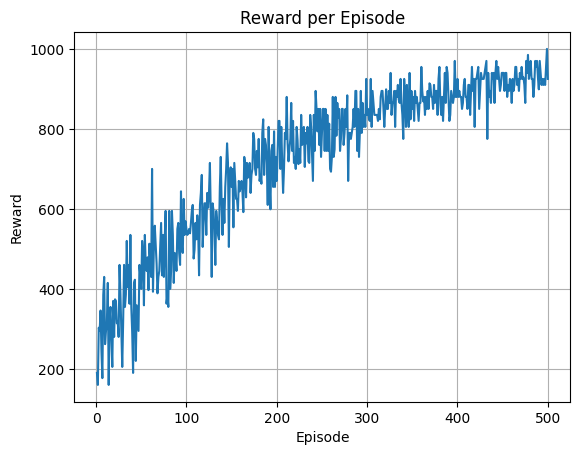

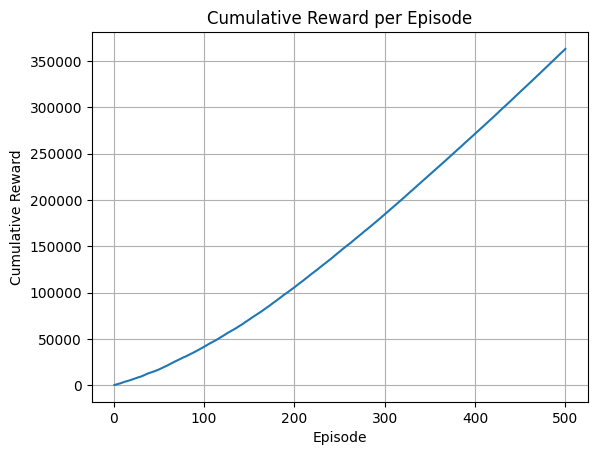

In [10]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(range(1, episodes + 1), episode_rewards)
plt.title("Reward per Episode")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.grid(True)
plt.savefig("reward_per_episode.png", bbox_inches="tight")
plt.show()

plt.figure()
plt.plot(range(1, episodes + 1), cumulative_rewards)
plt.title("Cumulative Reward per Episode")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.grid(True)
plt.savefig("cumulative_reward_per_episode.png", bbox_inches="tight")
plt.show()


### Learning performance

Compare the first 100 episodes with the last 100. A higher average reward near the end means the training actions earned more reward, although the decrease in random exploration also affects this comparison.


In [11]:
first_100 = sum(episode_rewards[:100]) / 100
last_100 = sum(episode_rewards[-100:]) / 100

print("Average reward (first 100):", round(first_100, 2))
print("Average reward (last 100):", round(last_100, 2))
print("Total cumulative reward:", cumulative_rewards[-1])

if last_100 > first_100:
    print("Rewards improved during training.")
else:
    print("Rewards did not improve during training.")

print("Lower epsilon means fewer random heater actions near the end.")
print("This model uses fixed transitions, not real temperature readings.")


Average reward (first 100): 413.25
Average reward (last 100): 917.06
Total cumulative reward: 363251
Rewards improved during training.
Lower epsilon means fewer random heater actions near the end.
This model uses fixed transitions, not real temperature readings.
